In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

import warnings
warnings.filterwarnings("ignore")


In [3]:
# 1. LOAD DATASET

df = pd.read_csv("uber.csv")

print("Original Shape:", df.shape)
print(df.head())


# 2. PREPROCESSING

# Remove unnecessary columns
df.drop(["Unnamed: 0", "key"], axis=1, inplace=True)

# Remove missing values
df.dropna(inplace=True)

# Convert datetime
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"])

# Extract date/time features
df["year"] = df["pickup_datetime"].dt.year
df["month"] = df["pickup_datetime"].dt.month
df["day"] = df["pickup_datetime"].dt.day
df["hour"] = df["pickup_datetime"].dt.hour
df["day_of_week"] = df["pickup_datetime"].dt.dayofweek

# Remove original datetime
df.drop("pickup_datetime", axis=1, inplace=True)



# 3. REMOVE INVALID VALUES

df = df[
    (df["pickup_longitude"] >= -74.3) &
    (df["pickup_longitude"] <= -73.7) &
    (df["dropoff_longitude"] >= -74.3) &
    (df["dropoff_longitude"] <= -73.7) &
    (df["pickup_latitude"] >= 40.4) &
    (df["pickup_latitude"] <= 41.0) &
    (df["dropoff_latitude"] >= 40.4) &
    (df["dropoff_latitude"] <= 41.0)
]

df = df[
    (df["fare_amount"] > 0) &
    (df["passenger_count"] > 0) &
    (df["passenger_count"] <= 6)
]


# 4. CALCULATE DISTANCE

def haversine_distance(lat1, lon1, lat2, lon2):

    R = 6371

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)

    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1)
        * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    c = 2 * np.arcsin(np.sqrt(a))

    return R * c


df["distance_km"] = haversine_distance(
    df["pickup_latitude"],
    df["pickup_longitude"],
    df["dropoff_latitude"],
    df["dropoff_longitude"]
)


Original Shape: (200000, 9)
   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647  


Shape after preprocessing: (170451, 12)


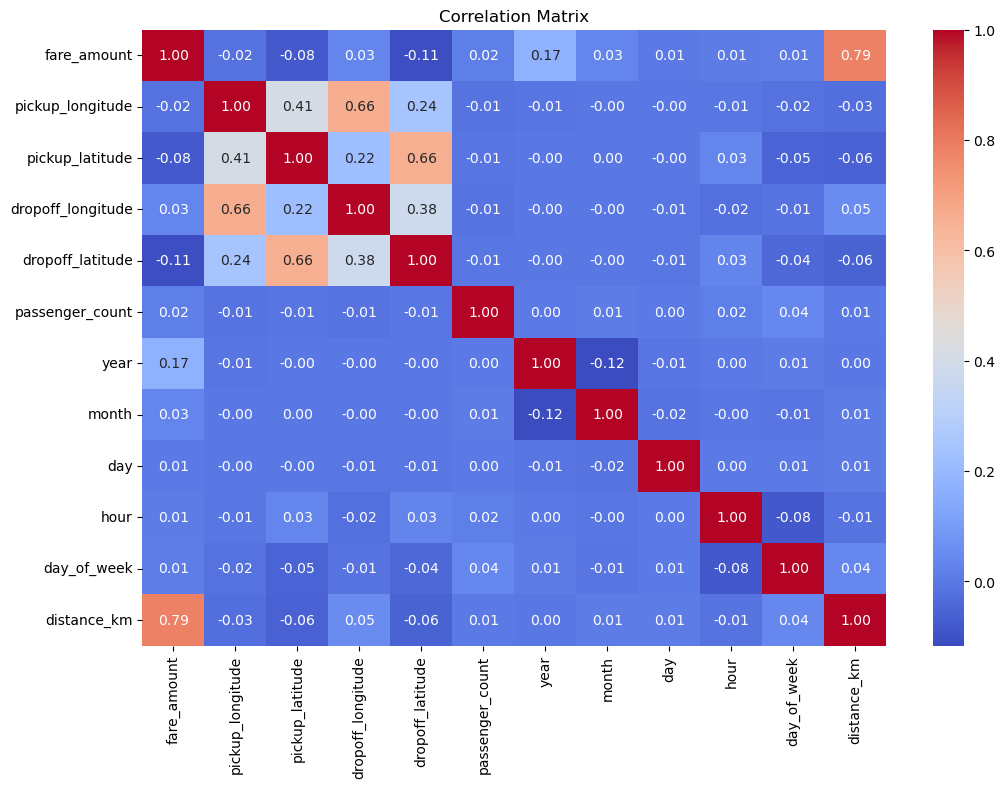

In [4]:
# 5. OUTLIER REMOVAL

def remove_outliers_iqr(data, column):

    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    return data[
        (data[column] >= lower) &
        (data[column] <= upper)
    ]


df = remove_outliers_iqr(df, "fare_amount")
df = remove_outliers_iqr(df, "distance_km")


print("\nShape after preprocessing:", df.shape)


# 6. CORRELATION

plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()


# 7. FEATURES AND TARGET

features = [
    "pickup_longitude",
    "pickup_latitude",
    "dropoff_longitude",
    "dropoff_latitude",
    "passenger_count",
    "year",
    "month",
    "day",
    "hour",
    "day_of_week",
    "distance_km"
]

X = df[features]
y = df["fare_amount"]


In [5]:
# 8. TRAIN TEST SPLIT

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)


# 9. LINEAR REGRESSION

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

y_pred_linear = linear_model.predict(X_test)


linear_r2 = r2_score(
    y_test,
    y_pred_linear
)

linear_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_linear
    )
)

linear_mae = mean_absolute_error(
    y_test,
    y_pred_linear
)


# 10. RANDOM FOREST

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)


rf_r2 = r2_score(
    y_test,
    y_pred_rf
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_rf
    )
)

rf_mae = mean_absolute_error(
    y_test,
    y_pred_rf
)


In [7]:
# 11. MODEL COMPARISON

results = pd.DataFrame({

    "Model": [
        "Linear Regression",
        "Random Forest Regression"
    ],

    "R2 Score": [
        linear_r2,
        rf_r2
    ],

    "RMSE": [
        linear_rmse,
        rf_rmse
    ],

    "MAE": [
        linear_mae,
        rf_mae
    ]
})


print("\n================ MODEL COMPARISON ================")
print(results)


# 12. FEATURE IMPORTANCE

importance = pd.DataFrame({

    "Feature": X.columns,

    "Importance":
        rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print("\nRandom Forest Feature Importance:")
print(importance)


================ MODEL COMPARISON ================
                      Model  R2 Score      RMSE       MAE
0         Linear Regression  0.651653  2.202981  1.554218
1  Random Forest Regression  0.735047  1.921273  1.318049

Random Forest Feature Importance:
              Feature  Importance
10        distance_km    0.670708
5                year    0.051663
3    dropoff_latitude    0.049003
2   dropoff_longitude    0.044346
0    pickup_longitude    0.040919
1     pickup_latitude    0.037139
8                hour    0.034417
7                 day    0.024424
6               month    0.021656
9         day_of_week    0.017685
4     passenger_count    0.008039
